# Cuaderno 02: Análisis Exploratorio de Datos (EDA) - Titanic
Este cuaderno implementa el diagnóstico sobre Bronze y la exploración estadística y visual sobre Silver y Gold.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from scipy import stats

from flows.common.paths import BRONZE, BRONZE_LABELED_NAME, SILVER, SILVER_NAME

# Estilo global
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.figsize'] = (8, 5)
plt.rcParams['axes.titlesize'] = 13

# Carga de Bronze: diagnóstico inicial sobre datos crudos
df_bronze = pd.read_csv(BRONZE / BRONZE_LABELED_NAME)


## Parte 1 — Primer contacto con los datos (Bronze)
### Paso 1: Dimensiones

In [2]:
print(f"Filas y columnas en Bronze: {df_bronze.shape}")
df_bronze.shape

Filas y columnas en Bronze: (891, 12)


(891, 12)

### Paso 2: Tipos de datos y valores no nulos

In [3]:
df_bronze.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    float64
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(3), int64(4), str(5)
memory usage: 118.9 KB


### Paso 3: Primeras 10 filas

In [4]:
df_bronze.head(10)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0.0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1.0,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1.0,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1.0,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0.0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
5,6,0.0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
6,7,0.0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
7,8,0.0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S
8,9,1.0,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S
9,10,1.0,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C


### Paso 4: Estadísticas descriptivas

In [5]:
display(df_bronze.describe())
display(df_bronze.select_dtypes(exclude="number").describe())

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


,Name,Sex,Ticket,Cabin,Embarked
count,891,891,891,204,889
unique,891,2,681,147,3
top,"Braund, Mr. Owen Harris",male,347082,G6,S
freq,1,577,7,4,644


### Paso 5: Identificación de datos faltantes en Bronze

Valores nulos por columna:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


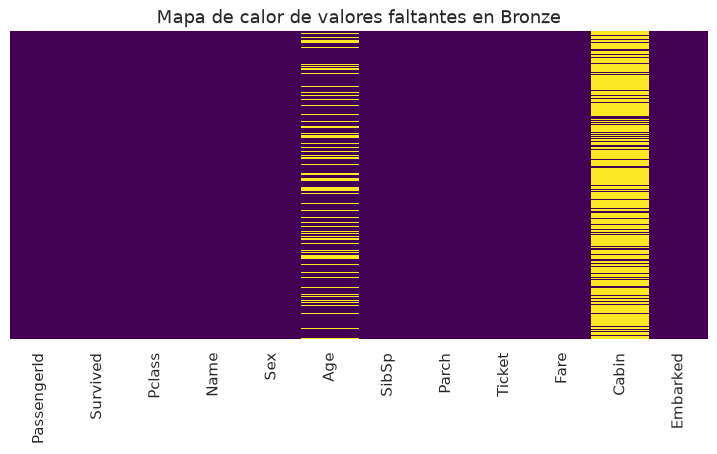

In [6]:
print("Valores nulos por columna:")
print(df_bronze.isnull().sum())

plt.figure(figsize=(9, 4))
sns.heatmap(df_bronze.isnull(), cbar=False, yticklabels=False, cmap='viridis')
plt.title('Mapa de calor de valores faltantes en Bronze')
plt.show()


## Parte 2 — Conociendo a los pasajeros (Capa Silver)
A partir de aquí consumimos data/silver/titanic_silver.parquet generado de forma determinista y reproducible por flows/01_data_engineering.py.

In [7]:
df = pd.read_parquet(SILVER / SILVER_NAME)
print(f"Capa Silver cargada con {df.shape[0]} filas y {df.shape[1]} columnas.")
df.head(5)


Capa Silver cargada con 891 filas y 25 columnas.


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,...,Familia,Alone,Survivor,TTitulo,AgeOriginal,AgeImputada,NSex,NEmbarked,NCabin,NTitulo
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,...,1,with Family,No,Mr,22.0,False,1,0,8,0
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,...,1,with Family,Yes,Mrs,38.0,False,0,1,2,1
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,...,0,Alone,Yes,Miss,26.0,False,0,0,8,2
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,...,1,with Family,Yes,Mrs,35.0,False,0,0,2,1
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,...,0,Alone,No,Mr,35.0,False,1,0,8,0


### Paso 6: Distribución por género y cruce con la clase

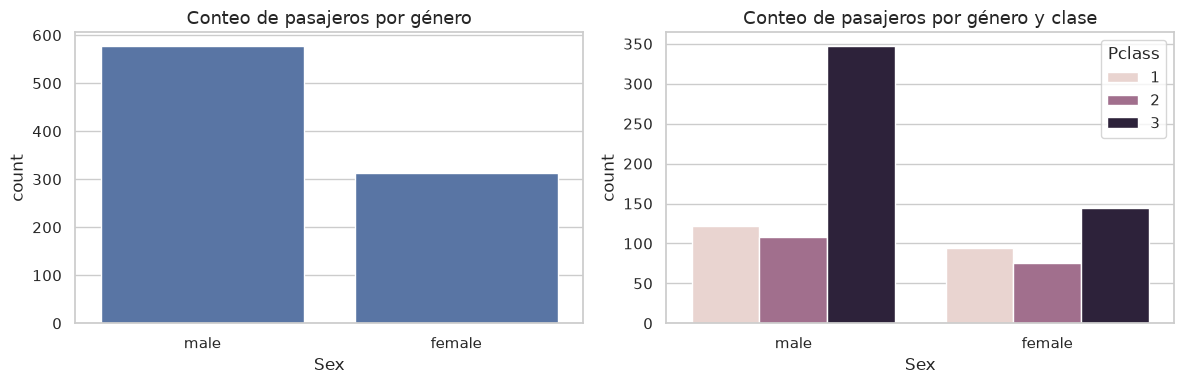

Pclass,1,2,3
Sex,,,
female,0.435,0.413,0.293
male,0.565,0.587,0.707


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=df, x='Sex', ax=axes[0])
axes[0].set_title('Conteo de pasajeros por género')

sns.countplot(data=df, x='Sex', hue='Pclass', ax=axes[1])
axes[1].set_title('Conteo de pasajeros por género y clase')
plt.tight_layout()
plt.show()

# Proporción de cada clase por género (normalizado por columnas)
pd.crosstab(df['Sex'], df['Pclass'], normalize='columns').round(3)


### Paso 7: Distribución de edades

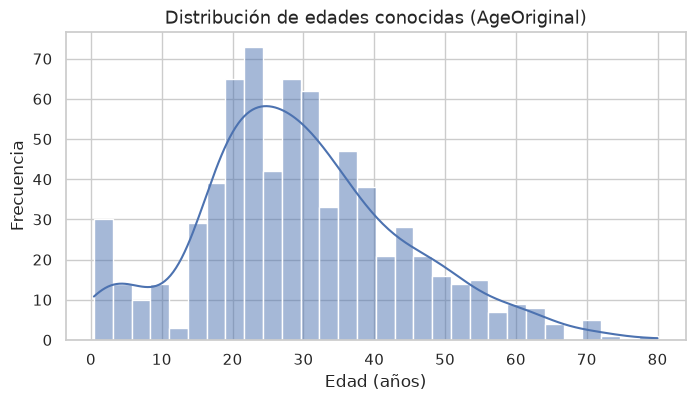

Edad promedio: 29.70
Mediana: 28.00, Mínimo: 0.42, Máximo: 80.00


In [9]:
plt.figure(figsize=(8, 4))
sns.histplot(df['AgeOriginal'].dropna(), bins=30, kde=True)
plt.title('Distribución de edades conocidas (AgeOriginal)')
plt.xlabel('Edad (años)')
plt.ylabel('Frecuencia')
plt.show()

print(f"Edad promedio: {df['AgeOriginal'].mean():.2f}")
print(f"Mediana: {df['AgeOriginal'].median():.2f}, Mínimo: {df['AgeOriginal'].min():.2f}, Máximo: {df['AgeOriginal'].max():.2f}")


### Paso 8: Variable derivada Person (niño, mujer, hombre)

In [10]:
print("Distribución de la variable Person:")
print(df['Person'].value_counts())


Distribución de la variable Person:
Person
male      537
female    271
child      83
Name: count, dtype: int64


### Paso 9: Niños por clase

In [11]:
pd.crosstab(df["Pclass"], df["Person"])

Person,child,female,male
Pclass,,,
1,6,91,119
2,19,66,99
3,58,114,319


### Paso 10: Gráficos de densidad (KDE) de la edad

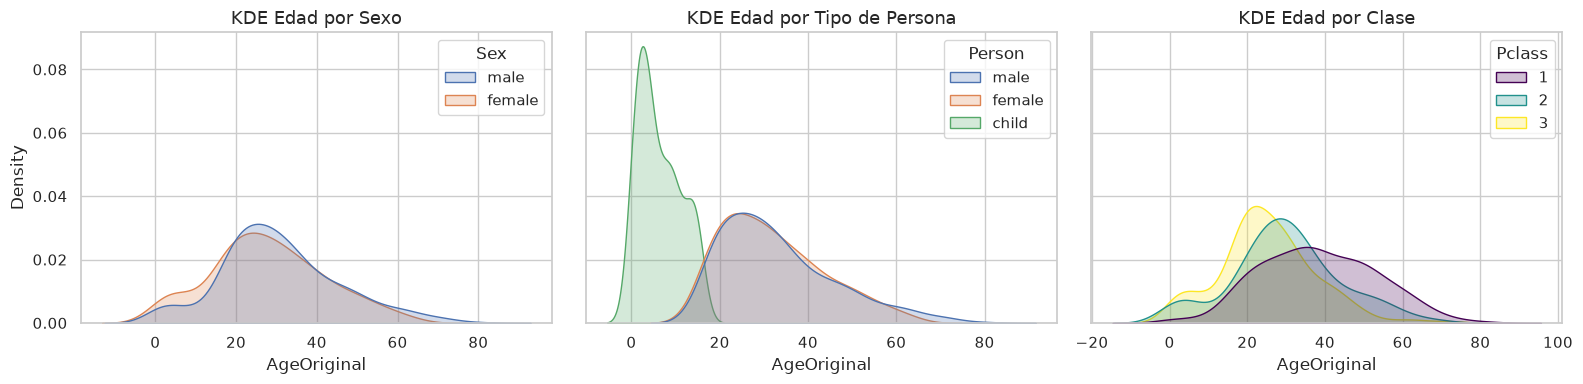

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
sns.kdeplot(data=df, x='AgeOriginal', hue='Sex', fill=True, common_norm=False, ax=axes[0])
axes[0].set_title('KDE Edad por Sexo')

sns.kdeplot(data=df, x='AgeOriginal', hue='Person', fill=True, common_norm=False, ax=axes[1])
axes[1].set_title('KDE Edad por Tipo de Persona')

sns.kdeplot(data=df, x='AgeOriginal', hue='Pclass', fill=True, common_norm=False, palette='viridis', ax=axes[2])
axes[2].set_title('KDE Edad por Clase')

plt.tight_layout()
plt.show()


## Parte 3 — Ubicación, embarque y composición familiar
### Paso 11 y 12: Cubierta de la cabina (TCabin)

Conteos por cubierta (incluye X para desconocida):
TCabin
X    687
C     59
B     47
D     33
E     32
A     15
F     13
G      4
T      1
Name: count, dtype: int64


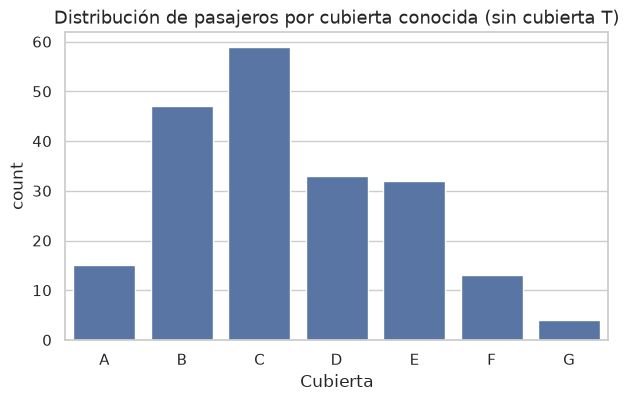

In [13]:
print("Conteos por cubierta (incluye X para desconocida):")
print(df['TCabin'].value_counts())

cubierta = df.loc[df['TCabin'] != 'X', 'TCabin']
# Excluyendo la cubierta T anómala solo de la visualización
cubierta_plot = cubierta[cubierta != 'T']

plt.figure(figsize=(7, 4))
sns.countplot(x=cubierta_plot, order=sorted(cubierta_plot.unique()))
plt.title('Distribución de pasajeros por cubierta conocida (sin cubierta T)')
plt.xlabel('Cubierta')
plt.show()


### Paso 13: Puerto de embarque y clase

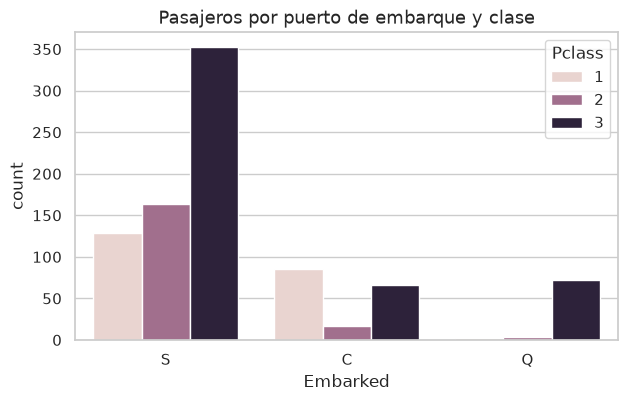

Pclass,1,2,3
Embarked,,,
C,0.506,0.101,0.393
Q,0.026,0.039,0.935
S,0.200,0.254,0.546


In [14]:
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x='Embarked', hue='Pclass', order=['S', 'C', 'Q'])
plt.title('Pasajeros por puerto de embarque y clase')
plt.show()

# Proporción de clases por puerto (normalizado por filas)
pd.crosstab(df['Embarked'], df['Pclass'], normalize='index').round(3)


### Pasos 14 y 15: Variable Alone (viajar solo vs. con familia)

Proporción de pasajeros solos vs. con familia:
Alone
Alone          0.603
with Family    0.397
Name: proportion, dtype: float64


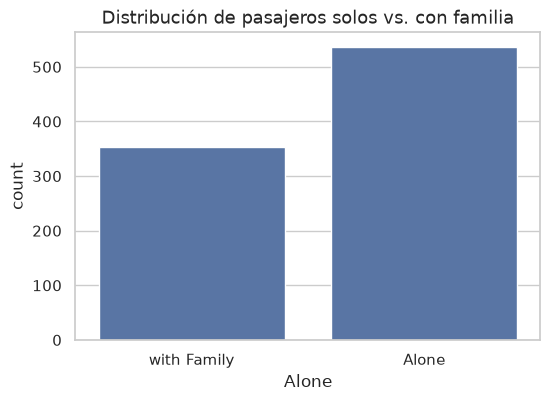

In [15]:
print("Proporción de pasajeros solos vs. con familia:")
print(df['Alone'].value_counts(normalize=True).round(3))

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Alone')
plt.title('Distribución de pasajeros solos vs. con familia')
plt.show()


## Parte 4 — Análisis de supervivencia (El núcleo del EDA)
### Paso 16: Panorama general de supervivencia

Tasa general de supervivencia: 0.3838


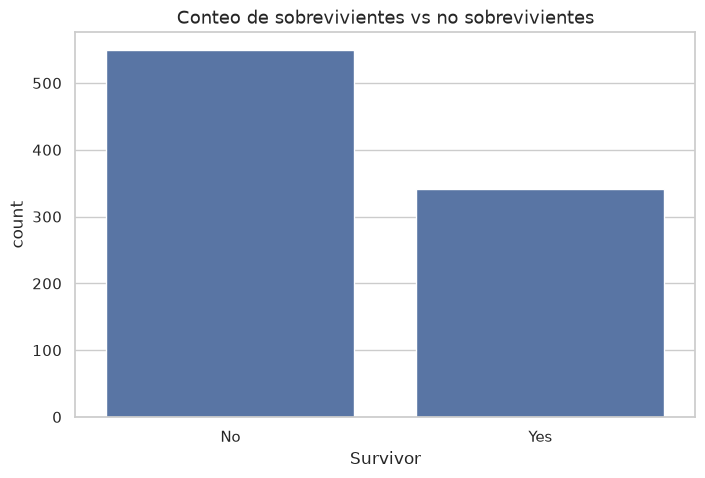

In [16]:
print(f"Tasa general de supervivencia: {df['Survived'].mean():.4f}")
sns.countplot(data=df, x='Survivor')
plt.title('Conteo de sobrevivientes vs no sobrevivientes')
plt.show()


### Pasos 17 y 18: Supervivencia por clase y persona

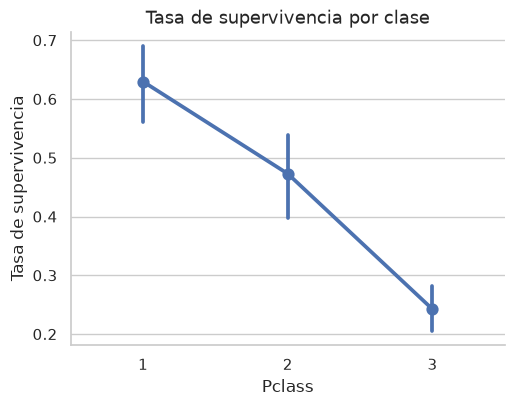

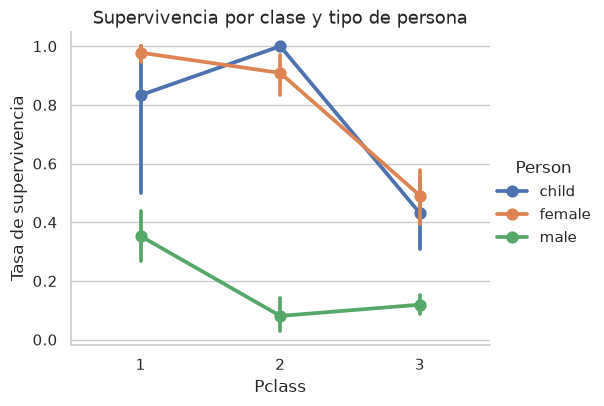

In [17]:
g1 = sns.catplot(data=df, x='Pclass', y='Survived', kind='point', height=4, aspect=1.3)
g1.ax.set_title('Tasa de supervivencia por clase')
g1.ax.set_ylabel('Tasa de supervivencia')
plt.show()

g2 = sns.catplot(data=df, x='Pclass', y='Survived', hue='Person',
                 hue_order=['child', 'female', 'male'], kind='point', height=4, aspect=1.3)
g2.ax.set_title('Supervivencia por clase y tipo de persona')
g2.ax.set_ylabel('Tasa de supervivencia')
plt.show()


### Paso 19: Relación entre edad y supervivencia

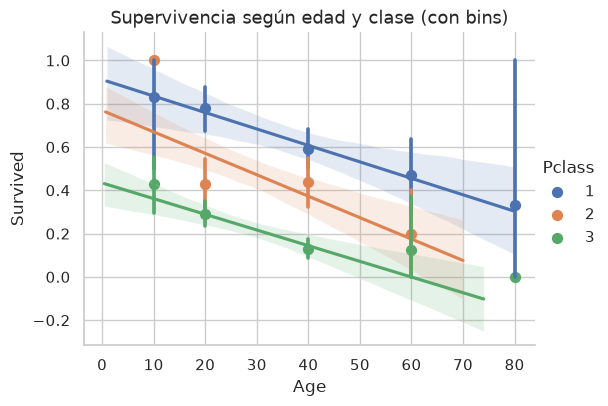

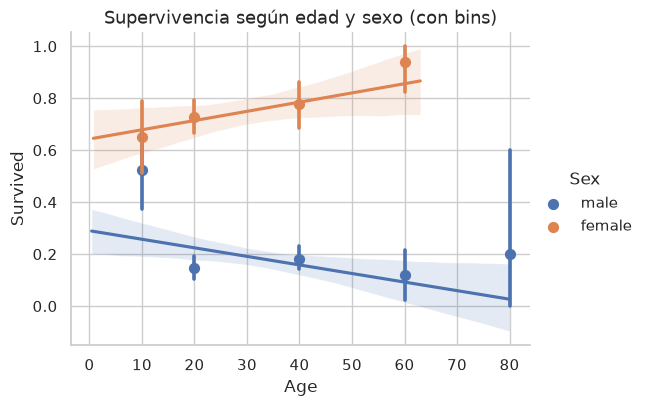

In [18]:
generaciones = [10, 20, 40, 60, 80]

sns.lmplot(data=df, x='Age', y='Survived', hue='Pclass', x_bins=generaciones, height=4, aspect=1.4)
plt.title('Supervivencia según edad y clase (con bins)')
plt.show()

sns.lmplot(data=df, x='Age', y='Survived', hue='Sex', x_bins=generaciones, height=4, aspect=1.4)
plt.title('Supervivencia según edad y sexo (con bins)')
plt.show()


### Paso 20: Dispersión Tarifa vs. Edad

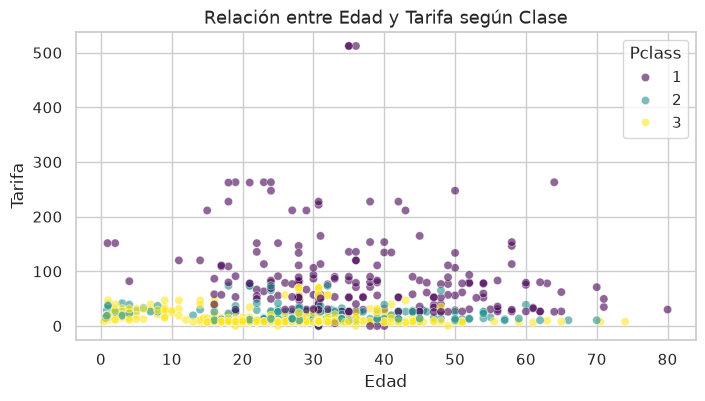

In [19]:
plt.figure(figsize=(8, 4))
sns.scatterplot(data=df, x='Age', y='Fare', hue='Pclass', alpha=0.6, palette='viridis')
plt.title('Relación entre Edad y Tarifa según Clase')
plt.xlabel('Edad')
plt.ylabel('Tarifa')
plt.show()


## Parte 5 y 6 — Correlaciones y estadísticas por grupos
### Pasos 25 y 26: Análisis de Títulos extraídos

In [20]:
print("Frecuencia de títulos consolidados (TTitulo):")
print(df['TTitulo'].value_counts())
print("\nCruce TTitulo x Sex:")
print(pd.crosstab(df['TTitulo'], df['Sex']))


Frecuencia de títulos consolidados (TTitulo):
TTitulo
Mr      557
Miss    186
Mrs     127
Otro     21
Name: count, dtype: int64

Cruce TTitulo x Sex:
Sex      female  male
TTitulo              
Miss        186     0
Mr            0   557
Mrs         127     0
Otro          1    20


### Paso 27: Matriz de correlación

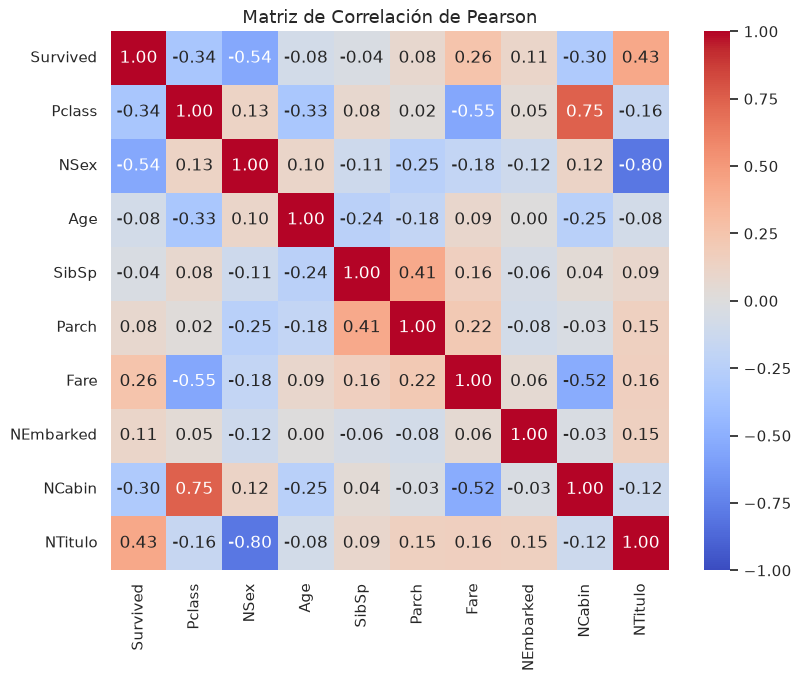

Correlaciones directas con Survived ordenadas:
NSex        -0.543351
Pclass      -0.338481
NCabin      -0.301116
Age         -0.080453
SibSp       -0.035322
Parch        0.081629
NEmbarked    0.106811
Fare         0.257307
NTitulo      0.428661
Survived     1.000000
Name: Survived, dtype: float64


In [21]:
cols = ['Survived', 'Pclass', 'NSex', 'Age', 'SibSp', 'Parch', 'Fare', 'NEmbarked', 'NCabin', 'NTitulo']
corr = df[cols].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Matriz de Correlación de Pearson')
plt.show()

print("Correlaciones directas con Survived ordenadas:")
print(corr['Survived'].sort_values())


### Paso 28 y 29: Estadísticas por grupo y prueba Chi-cuadrado

In [22]:
tabla_sex = pd.crosstab(df['Sex'], df['Survived'])
chi2, p_val, dof, _ = stats.chi2_contingency(tabla_sex)
print(f"Prueba Chi2 de Sexo vs Supervivencia: chi2 = {chi2:.2f}, p-value = {p_val:.2e}, dof = {dof}")


Prueba Chi2 de Sexo vs Supervivencia: chi2 = 260.72, p-value = 1.20e-58, dof = 1


## Parte 7 — Visualizaciones comparativas avanzadas
### Paso 30: Boxplots múltiples (2x2)

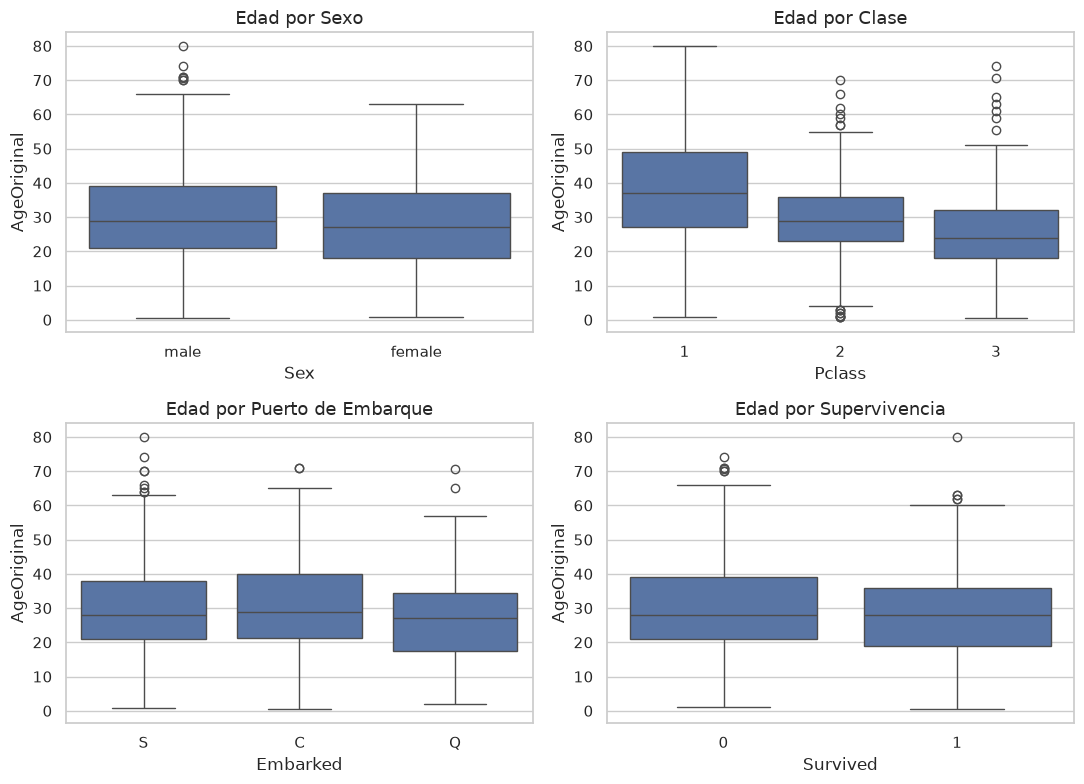

In [23]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
sns.boxplot(data=df, x='Sex', y='AgeOriginal', ax=axes[0, 0])
axes[0, 0].set_title('Edad por Sexo')

sns.boxplot(data=df, x='Pclass', y='AgeOriginal', ax=axes[0, 1])
axes[0, 1].set_title('Edad por Clase')

sns.boxplot(data=df, x='Embarked', y='AgeOriginal', ax=axes[1, 0])
axes[1, 0].set_title('Edad por Puerto de Embarque')

sns.boxplot(data=df, x='Survived', y='AgeOriginal', ax=axes[1, 1])
axes[1, 1].set_title('Edad por Supervivencia')

plt.tight_layout()
plt.show()


### Paso 31: Distribución y asimetría de la tarifa

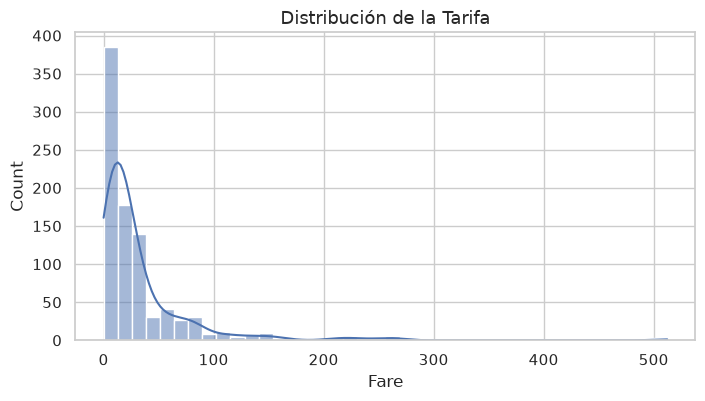

Media de Fare: 32.20
Mediana de Fare: 14.45
Asimetría (skewness) de Fare: 4.79


In [24]:
plt.figure(figsize=(8, 4))
sns.histplot(df['Fare'], kde=True, bins=40)
plt.title('Distribución de la Tarifa')
plt.show()

print(f"Media de Fare: {df['Fare'].mean():.2f}")
print(f"Mediana de Fare: {df['Fare'].median():.2f}")
print(f"Asimetría (skewness) de Fare: {df['Fare'].skew():.2f}")


## Parte 9 — Análisis crítico e interacciones (Gold)
### Paso 34: Interacciones Clase x Género

In [25]:
df.pivot_table(values="Survived", index="Pclass", columns="Sex", aggfunc="mean").round(3)

Sex,female,male
Pclass,,
1,0.968,0.369
2,0.921,0.157
3,0.500,0.135


### Paso 35: Puerto de embarque vs. Clase (Desacople de confusión)

In [26]:
display(df.groupby('Embarked')['Survived'].agg(['mean', 'count']).round(3))
display(df.pivot_table(values='Survived', index='Embarked', columns='Pclass', aggfunc='mean').round(3))


,mean,count
Embarked,,
C,0.554,168
Q,0.390,77
S,0.339,646


Pclass,1,2,3
Embarked,,,
C,0.694,0.529,0.379
Q,0.500,0.667,0.375
S,0.589,0.463,0.190


### Paso 36: Cuartiles de tarifa dentro de cada clase

In [27]:
df_gold = df.copy()
df_gold['FareQ'] = df_gold.groupby('Pclass')['Fare'].transform(lambda s: pd.qcut(s, 4, labels=False, duplicates='drop'))
df_gold.pivot_table(values='Survived', index='FareQ', columns='Pclass', aggfunc='mean').round(3)


Pclass,1,2,3
FareQ,,,
0,0.463,0.345,0.227
1,0.574,0.500,0.200
2,0.745,0.585,0.276
3,0.736,0.590,0.283


### Paso 37: Tamaño de la familia y supervivencia

,mean,count
Familia,,
0,0.303538,537
1,0.552795,161
2,0.578431,102
3,0.724138,29
4,0.200000,15
5,0.136364,22
6,0.333333,12
7,0.000000,6
10,0.000000,7


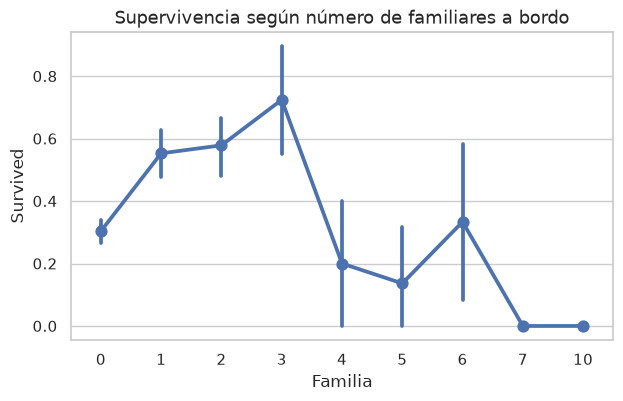

In [28]:
display(df.groupby('Familia')['Survived'].agg(['mean', 'count']))

plt.figure(figsize=(7, 4))
sns.pointplot(data=df, x='Familia', y='Survived')
plt.title('Supervivencia según número de familiares a bordo')
plt.show()


### Paso 38: Pasajeros atípicos (Criterio IQR)

In [29]:
def outlier_mask_iqr(s):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    return (s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)

for col in ['Fare', 'AgeOriginal', 'Familia']:
    s = df[col].dropna()
    print(f"Atípicos en {col}: {outlier_mask_iqr(s).sum()}")

fare_mask = outlier_mask_iqr(df['Fare'])
print("\nSupervivencia de atípicos de Fare vs. no atípicos:")
print(df.groupby(fare_mask)['Survived'].agg(['mean', 'count']))

print("\nTop 10 tarifas más altas registradas:")
df.nlargest(10, 'Fare')[['Name', 'Pclass', 'Fare', 'Survived']]


Atípicos en Fare: 116
Atípicos en AgeOriginal: 11
Atípicos en Familia: 91

Supervivencia de atípicos de Fare vs. no atípicos:
           mean  count
Fare                  
False  0.339355    775
True   0.681034    116

Top 10 tarifas más altas registradas:


,Name,Pclass,Fare,Survived
258,"Ward, Miss. Anna",1,512.3292,1
679,"Cardeza, Mr. Thomas Drake Martinez",1,512.3292,1
737,"Lesurer, Mr. Gustave J",1,512.3292,1
27,"Fortune, Mr. Charles Alexander",1,263.0000,0
88,"Fortune, Miss. Mabel Helen",1,263.0000,1
341,"Fortune, Miss. Alice Elizabeth",1,263.0000,1
438,"Fortune, Mr. Mark",1,263.0000,0
311,"Ryerson, Miss. Emily Borie",1,262.3750,1
742,"Ryerson, Miss. Susan Parker ""Suzette""",1,262.3750,1
118,"Baxter, Mr. Quigg Edmond",1,247.5208,0
